# Create a Simple Reflex-Based Lunar Lander Agent

In this example, we will use Gymnasium, an environment to train agents via reinforcement learning (RL). We will not use RL here but just use the environment with a custom simple reflex-based agent.

## Install Gymnasium

The documentation for Gymnasium is available at https://gymnasium.farama.org/

Steps:
1. Create a new folder and open it with VS Code and install all needed Python Extensions in VS Code.
2. Create a new virtual environment (CTRL-Shift P Python Create Environment...)
3. I needed to install swig and the Python C++ headers on WSL2 via the terminal
    * `sudo apt install swig`
    * `sudo apt-get install python3-dev`
4. Install python libraries for gymnasium with the needed extras

In [31]:
# Google Colab or if you are missing a package: Uncomment the %pip command below, run this block, and restart the session.
%pip install -q "swig>=4,<5" "gymnasium[box2d,classic-control]>=1.0,<2"

Additional installs for screen capturing so environment visualizations can be converted to embedded videos.
For recording videos, I had to install
    
* `sudo apt-get install xvfb ffmpeg`

Additional python packages for screen capturing.

In [32]:
# Google Colab or if you are missing a package: Uncomment the %pip command below, run this block, and restart the session.
%pip install -q "pyvirtualdisplay>=3,<4" "gymnasium[other]>=1.0,<2"

## The Lunar Lander Environment

![Luna Lander image](https://gymnasium.farama.org/_images/lunar_lander.gif)

The documentation of the environment is available at: https://gymnasium.farama.org/environments/box2d/lunar_lander/

* Performance Measure: A reward of -100 or +100 points for crashing or landing safely respectively. We do not use
  intermediate rewards here.

* Environment: This environment is a classic rocket trajectory optimization problem. A ship needs to land safely. The space is **continuous** with
  x and y coordinates in the range [-2.5, 2.5]. The landing pad is at coordinate (0,0).

* Actuators:  According to Pontryagin’s
  maximum principle, it is optimal to fire the engine at full throttle or turn it off. This is the reason why this environment has discrete actions: engine on or off. There are four discrete actions available:

    - 0: do nothing
    - 1: fire left orientation engine
    - 2: fire main engine
    - 3: fire right orientation engine

* Sensors: Each observation is an 8-dimensional vector: the coordinates of the lander in x & y, its linear velocities in x & y, its angle, its angular velocity, and two booleans that represent whether each leg is in contact with the ground or not.

The different ranges/settings of the environment can be queried.

In [33]:
import gymnasium as gym
import numpy as np
np.set_printoptions(precision=2)

In [34]:
def query_environment(name):
    env = gym.make(name)
    print(f"Action Space: {env.action_space}")
    print(f"Observation Space: {env.observation_space}")
    print(f"Max Episode Steps: {env.spec.max_episode_steps}")
    print(f"Nondeterministic: {env.spec.nondeterministic}")
   # print(f"Reward Range: {env.reward_range}")
    print(f"Reward Threshold: {env.spec.reward_threshold}")
    env.close()

query_environment("LunarLander-v3")

Action Space: Discrete(4)
Observation Space: Box([ -2.5   -2.5  -10.   -10.    -6.28 -10.    -0.    -0.  ], [ 2.5   2.5  10.   10.    6.28 10.    1.    1.  ], (8,), float32)
Max Episode Steps: 1000
Nondeterministic: False
Reward Threshold: 200



Gymnasium environments are implemented as classes with a `make` method to create the environment, a `reset` method, and a `step` method to execute an action.
To use it with an agent function that expects percepts and returns an action, we need write glue code that connects the environment with the agent function.

In [35]:
def run_episode(agent_function, env, max_steps=1000, verbose = True, render = True):
    """Run one episode in the environment using the provided agent."""

    # Reset the environment to generate the first observation (use seed=42 in reset to get reproducible results)
    observation, info = env.reset()

    # run one episode
    for _ in range(max_steps):
        # call the agent function to select an action
        action = agent_function(observation)

        if verbose:
            print (f"Obs: {observation} -> Action: {action}")

        # step: execute an action in the environment
        observation, reward, terminated, truncated, info = env.step(action)

        # render the environment
        if render:
            env.render()

        if terminated:
            if verbose:
                print(f"Final Reward: {reward}")
            break

    return reward

## Example: A Random Agent

We randomly return one of the actions. The environment accepts the integers 0-3.


In [36]:
def random_agent_function(observation):
    """A random agent that selects actions uniformly at random. It ignores the observation."""
    return np.random.choice([0, 1, 2, 3], p=[0.25, 0.25, 0.25, 0.25])

Run an episode.

In [37]:
env = gym.make("LunarLander-v3", render_mode="human")

run_episode(random_agent_function, env)

env.close()

Obs: [-0.    1.4  -0.18 -0.3   0.    0.04  0.    0.  ] -> Action: 2
Obs: [-0.    1.4  -0.17 -0.27  0.    0.05  0.    0.  ] -> Action: 2
Obs: [-0.01  1.39 -0.16 -0.24  0.01  0.06  0.    0.  ] -> Action: 0
Obs: [-0.01  1.39 -0.16 -0.26  0.01  0.06  0.    0.  ] -> Action: 0
Obs: [-0.01  1.38 -0.16 -0.29  0.01  0.06  0.    0.  ] -> Action: 1
Obs: [-0.01  1.37 -0.17 -0.32  0.02  0.09  0.    0.  ] -> Action: 0
Obs: [-0.01  1.37 -0.17 -0.34  0.02  0.09  0.    0.  ] -> Action: 1
Obs: [-0.01  1.36 -0.18 -0.37  0.03  0.13  0.    0.  ] -> Action: 1
Obs: [-0.02  1.35 -0.19 -0.4   0.04  0.17  0.    0.  ] -> Action: 3
Obs: [-0.02  1.34 -0.18 -0.42  0.04  0.12  0.    0.  ] -> Action: 1
Obs: [-0.02  1.33 -0.19 -0.45  0.05  0.17  0.    0.  ] -> Action: 1
Obs: [-0.02  1.32 -0.2  -0.48  0.06  0.21  0.    0.  ] -> Action: 0
Obs: [-0.02  1.31 -0.2  -0.5   0.07  0.21  0.    0.  ] -> Action: 1
Obs: [-0.02  1.29 -0.21 -0.53  0.09  0.24  0.    0.  ] -> Action: 0
Obs: [-0.03  1.28 -0.21 -0.56  0.1   0.24  0.   

Gymnasium displays environments using `render()` method on the local display. Headless installations like Google Colab do not have a display, but the output can be captured using a virtual display as a video and then add the video to the notebook.

We need to start a virtual display.

Now we can use wrappers for the environment to record the display. The functions are provided in
[display_record.py].



In [38]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("gymnasium_display_recorder.py",
         "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Agents/")

In [39]:
import gymnasium_display_recorder as dr

env = dr.gym_make('LunarLander-v3', 'LL1', render_fps=30)
run_episode(random_agent_function, env, verbose=False)
env.close()

dr.show('LL1')

/usr/local/lib/python3.13/dist-packages/gymnasium/wrappers/rendering.py:292: UserWarning: WARN: Overwriting existing videos at /content/videos folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


## A Simple Reflex-Based Agent

To make the code easier to read, we use enumerations for actions (integers) and observations (index in the observation vector).

In [40]:
from enum import Enum

class Act(Enum):
    LEFT = 1
    RIGHT = 3
    MAIN = 2
    NO_OP = 0

class Obs(Enum):
    X = 0
    Y = 1
    VX = 2
    VY = 3
    ANGLE = 4
    ANGULAR_VELOCITY = 5
    LEFT_LEG_CONTACT = 6
    RIGHT_LEG_CONTACT = 7


Define a simple agent that uses the main thruster to reduce the falling speed if it gets too fast.

In [41]:
def rocket_agent_function(observation):
    """A simple agent function."""

    # run the main thruster, if the lander is falling too fast
    if observation[Obs.VY.value] < -.4:
        return Act.MAIN.value

    return Act.NO_OP.value

In [42]:
env = dr.gym_make('LunarLander-v3', 'LL2', render_fps=30)
run_episode(rocket_agent_function, env, verbose = False)
env.close()

dr.show('LL2')

## Evaluating the Agent

Run the agent on 100 problems and report the average reward.

In [43]:
def run_episodes(agent_function, env, n=1000):
    """Run multiple episodes with the given agent and return the rewards for each episode."""
    return [run_episode(agent_function, env, verbose=False, render=False) for _ in range(n)]

Run experiments.

In [44]:
env = gym.make("LunarLander-v3", render_mode=None)

rewards = run_episodes(rocket_agent_function, env)
print(rewards)

print(f"Average reward: {np.average(rewards)}")
print(f"Success rate: {np.sum(np.array(rewards) == 100)}/{len(rewards)}")

[-100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -10

This is not great performance!


## Implement A Better Reflex-Based Agent

Build a better that uses its right and left thrusters to land the craft (more) safely. Test your agent function using 100 problems.

X                  → tàu lệch trái/phải bao nhiêu \
VX                 → tàu đang trôi ngang theo hướng nào \
VY                 → tốc độ rơi\
ANGLE              → độ nghiêng\
ANGULAR_VELOCITY   → tốc độ quay\
LEG CONTACT        → tàu đã chạm đất chưa\

In [54]:
def better_reflex_agent_function(observation):
    """
    Improved reflex-based Lunar Lander agent.

    The agent uses:
    - horizontal position (x)
    - horizontal velocity (vx)
    - vertical velocity (vy)
    - angle
    - angular velocity
    - leg contact

    Actions:
        0 = no operation
        1 = left orientation engine
        2 = main engine
        3 = right orientation engine
    """

    # ---------------------------------------------------------
    # 1. Read observation
    # ---------------------------------------------------------
    x = observation[Obs.X.value]
    y = observation[Obs.Y.value]

    vx = observation[Obs.VX.value]
    vy = observation[Obs.VY.value]

    angle = observation[Obs.ANGLE.value]
    angular_velocity = observation[
        Obs.ANGULAR_VELOCITY.value
    ]

    left_contact = observation[
        Obs.LEFT_LEG_CONTACT.value
    ]

    right_contact = observation[
        Obs.RIGHT_LEG_CONTACT.value
    ]

    # ---------------------------------------------------------
    # 2. If the lander has touched the ground,
    #    mainly reduce the remaining falling speed.
    # ---------------------------------------------------------
    if left_contact or right_contact:

        if vy < -0.10:
            return Act.MAIN.value

        return Act.NO_OP.value

    # ---------------------------------------------------------
    # 3. Desired angle
    #
    # If the lander is horizontally far from the landing pad
    # or moving away from it, allow a small tilt toward center.
    # ---------------------------------------------------------
    target_angle = (
        0.5 * x
        + 0.8 * vx
    )

    # Avoid excessive tilt
    target_angle = np.clip(
        target_angle,
        -0.35,
        0.35
    )

    # ---------------------------------------------------------
    # 4. Calculate how much rotational correction is needed
    # ---------------------------------------------------------
    angle_error = (
        target_angle
        - angle
    )

    rotation_control = (
        0.6 * angle_error
        - 0.8 * angular_velocity
    )

    # ---------------------------------------------------------
    # 5. Horizontal / angular correction
    # ---------------------------------------------------------

    # Need more positive rotation
    if rotation_control > 0.06:
        return Act.LEFT.value

    # Need more negative rotation
    if rotation_control < -0.06:
        return Act.RIGHT.value

    # ---------------------------------------------------------
    # 6. Vertical control
    #
    # When the lander falls too quickly and is sufficiently
    # stable, fire the main engine.
    # ---------------------------------------------------------
    safe_descent_speed = -0.35

    if vy < safe_descent_speed:
        return Act.MAIN.value

    # ---------------------------------------------------------
    # 7. Near the landing pad:
    #    use a slightly stricter descent threshold
    # ---------------------------------------------------------
    if abs(x) < 0.15 and vy < -0.20:
        return Act.MAIN.value

    # ---------------------------------------------------------
    # 8. Otherwise do nothing to save fuel
    # ---------------------------------------------------------
    return Act.NO_OP.value

Test Better Reflex Agent một episode

In [56]:
env = dr.gym_make(
    "LunarLander-v3",
    "LL3",
    render_fps=30
)

run_episode(
    better_reflex_agent_function,
    env,
    verbose=True
)

env.close()

dr.show("LL3")

/usr/local/lib/python3.13/dist-packages/gymnasium/wrappers/rendering.py:292: UserWarning: WARN: Overwriting existing videos at /content/videos folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


Obs: [ 0.01  1.4   0.68 -0.51 -0.01 -0.15  0.    0.  ] -> Action: 1
Obs: [ 0.01  1.39  0.67 -0.54 -0.01 -0.1   0.    0.  ] -> Action: 1
Obs: [ 0.02  1.37  0.65 -0.57 -0.02 -0.06  0.    0.  ] -> Action: 1
Obs: [ 0.03  1.36  0.65 -0.59 -0.02 -0.03  0.    0.  ] -> Action: 1
Obs: [ 0.03  1.35  0.64 -0.62 -0.02  0.02  0.    0.  ] -> Action: 1
Obs: [ 0.04  1.33  0.63 -0.65 -0.01  0.06  0.    0.  ] -> Action: 1
Obs: [ 0.05  1.32  0.62 -0.67 -0.01  0.1   0.    0.  ] -> Action: 1
Obs: [ 0.05  1.3   0.61 -0.7  -0.    0.13  0.    0.  ] -> Action: 1
Obs: [ 0.06  1.29  0.6  -0.73  0.01  0.17  0.    0.  ] -> Action: 1
Obs: [ 0.06  1.27  0.59 -0.75  0.02  0.21  0.    0.  ] -> Action: 2
Obs: [ 0.07  1.25  0.57 -0.72  0.03  0.2   0.    0.  ] -> Action: 2
Obs: [ 0.07  1.24  0.56 -0.7   0.04  0.19  0.    0.  ] -> Action: 2
Obs: [ 0.08  1.22  0.56 -0.7   0.05  0.19  0.    0.  ] -> Action: 2
Obs: [ 0.09  1.21  0.56 -0.68  0.06  0.19  0.    0.  ] -> Action: 2
Obs: [ 0.09  1.19  0.54 -0.67  0.06  0.17  0.   

Đánh giá đúng 100 episodes

In [57]:
def run_episodes(agent_function, env, n=1000):
    """Run multiple episodes with the given agent."""

    return [
        run_episode(
            agent_function,
            env,
            verbose=True,
            render=False
        )
        for _ in range(n)
    ]

chạy Random Agent

In [58]:
env = gym.make(
    "LunarLander-v3",
    render_mode=None
)

random_rewards = run_episodes(
    random_agent_function,
    env,
    n=100
)

env.close()

Streaming output truncated to the last 5000 lines.
Obs: [ 0.25  0.88  0.8  -1.    0.   -0.03  0.    0.  ] -> Action: 1
Obs: [ 0.26  0.85  0.8  -1.03  0.    0.01  0.    0.  ] -> Action: 2
Obs: [ 0.27  0.83  0.78 -1.    0.   -0.01  0.    0.  ] -> Action: 1
Obs: [ 0.27  0.81  0.77 -1.02  0.01  0.04  0.    0.  ] -> Action: 0
Obs: [ 0.28  0.78  0.77 -1.05  0.01  0.04  0.    0.  ] -> Action: 1
Obs: [ 0.29  0.76  0.76 -1.08  0.01  0.08  0.    0.  ] -> Action: 1
Obs: [ 0.3   0.73  0.75 -1.1   0.02  0.12  0.    0.  ] -> Action: 0
Obs: [ 0.3   0.71  0.75 -1.13  0.02  0.12  0.    0.  ] -> Action: 1
Obs: [ 0.31  0.68  0.74 -1.16  0.03  0.16  0.    0.  ] -> Action: 2
Obs: [ 0.32  0.66  0.73 -1.15  0.04  0.16  0.    0.  ] -> Action: 2
Obs: [ 0.33  0.63  0.74 -1.13  0.05  0.17  0.    0.  ] -> Action: 0
Obs: [ 0.33  0.61  0.74 -1.16  0.06  0.17  0.    0.  ] -> Action: 1
Obs: [ 0.34  0.58  0.74 -1.19  0.07  0.21  0.    0.  ] -> Action: 2
Obs: [ 0.35  0.55  0.74 -1.17  0.08  0.21  0.    0.  ] -> Action:

Simple Reflex Agent

In [59]:
env = gym.make(
    "LunarLander-v3",
    render_mode=None
)

simple_rewards = run_episodes(
    rocket_agent_function,
    env,
    n=100
)

env.close()

Streaming output truncated to the last 5000 lines.
Obs: [-0.69  0.62 -1.02 -0.4   0.07 -0.05  0.    0.  ] -> Action: 0
Obs: [-0.7   0.61 -1.02 -0.43  0.07 -0.05  0.    0.  ] -> Action: 2
Obs: [-0.71  0.6  -1.04 -0.42  0.07 -0.07  0.    0.  ] -> Action: 2
Obs: [-0.72  0.59 -1.04 -0.41  0.07 -0.06  0.    0.  ] -> Action: 2
Obs: [-0.73  0.58 -1.05 -0.4   0.06 -0.07  0.    0.  ] -> Action: 0
Obs: [-0.74  0.58 -1.05 -0.42  0.06 -0.07  0.    0.  ] -> Action: 2
Obs: [-0.75  0.57 -1.07 -0.41  0.05 -0.08  0.    0.  ] -> Action: 2
Obs: [-0.76  0.56 -1.06 -0.36  0.05 -0.07  0.    0.  ] -> Action: 0
Obs: [-0.77  0.55 -1.06 -0.39  0.05 -0.07  0.    0.  ] -> Action: 0
Obs: [-0.78  0.54 -1.06 -0.42  0.04 -0.07  0.    0.  ] -> Action: 2
Obs: [-0.79  0.53 -1.05 -0.39  0.04 -0.05  0.    0.  ] -> Action: 0
Obs: [-0.8   0.52 -1.05 -0.42  0.04 -0.05  0.    0.  ] -> Action: 2
Obs: [-0.81  0.51 -1.05 -0.38  0.04 -0.05  0.    0.  ] -> Action: 0
Obs: [-0.82  0.5  -1.05 -0.4   0.03 -0.05  0.    0.  ] -> Action:

Improved Reflex Agent

In [60]:
env = gym.make(
    "LunarLander-v3",
    render_mode=None
)

better_rewards = run_episodes(
    better_reflex_agent_function,
    env,
    n=100
)

env.close()

Streaming output truncated to the last 5000 lines.
Obs: [ 0.06  0.32 -0.04 -0.23  0.04 -0.02  0.    0.  ] -> Action: 2
Obs: [ 0.06  0.31 -0.03 -0.22  0.04 -0.    0.    0.  ] -> Action: 2
Obs: [ 0.06  0.31 -0.04 -0.19  0.04 -0.02  0.    0.  ] -> Action: 0
Obs: [ 0.06  0.3  -0.04 -0.22  0.04 -0.02  0.    0.  ] -> Action: 2
Obs: [ 0.06  0.3  -0.05 -0.19  0.04 -0.02  0.    0.  ] -> Action: 0
Obs: [ 0.06  0.29 -0.05 -0.22  0.04 -0.02  0.    0.  ] -> Action: 2
Obs: [ 0.05  0.29 -0.04 -0.22  0.04 -0.01  0.    0.  ] -> Action: 2
Obs: [ 0.05  0.28 -0.06 -0.19  0.03 -0.03  0.    0.  ] -> Action: 0
Obs: [ 0.05  0.28 -0.06 -0.22  0.03 -0.03  0.    0.  ] -> Action: 2
Obs: [ 0.05  0.27 -0.05 -0.22  0.03 -0.02  0.    0.  ] -> Action: 2
Obs: [ 0.05  0.27 -0.06 -0.18  0.03 -0.02  0.    0.  ] -> Action: 0
Obs: [ 0.05  0.26 -0.06 -0.21  0.03 -0.02  0.    0.  ] -> Action: 2
Obs: [ 0.05  0.26 -0.05 -0.19  0.03 -0.01  0.    0.  ] -> Action: 0
Obs: [ 0.05  0.26 -0.05 -0.21  0.03 -0.01  0.    0.  ] -> Action:

### Hàm tính thống kê

In [61]:
def calculate_statistics(rewards):
    """
    Calculate evaluation statistics
    for one Lunar Lander agent.
    """

    rewards = np.array(
        rewards,
        dtype=float
    )

    return {
        "Average Reward":
            np.mean(rewards),

        "Std Reward":
            np.std(rewards),

        "Min Reward":
            np.min(rewards),

        "Max Reward":
            np.max(rewards),

        "Successful Landings":
            np.sum(rewards == 100),

        "Success Rate (%)":
            np.mean(rewards == 100) * 100
    }

Tạo bảng so sánh cả ba agent

In [62]:
import pandas as pd


random_stats = calculate_statistics(
    random_rewards
)

simple_stats = calculate_statistics(
    simple_rewards
)

better_stats = calculate_statistics(
    better_rewards
)


results = pd.DataFrame([
    {
        "Agent": "Random Agent",
        **random_stats
    },

    {
        "Agent": "Simple Reflex Agent",
        **simple_stats
    },

    {
        "Agent": "Improved Reflex Agent",
        **better_stats
    }
])


numeric_columns = [
    "Average Reward",
    "Std Reward",
    "Min Reward",
    "Max Reward",
    "Success Rate (%)"
]


results[numeric_columns] = (
    results[numeric_columns]
    .round(2)
)


results

,Agent,Average Reward,Std Reward,Min Reward,Max Reward,Successful Landings,Success Rate (%)
0,Random Agent,-100.0,0.0,-100.0,-100.0,0,0.0
1,Simple Reflex Agent,-98.0,19.9,-100.0,100.0,1,1.0
2,Improved Reflex Agent,100.0,0.0,100.0,100.0,100,100.0


Biểu đồ Average Reward

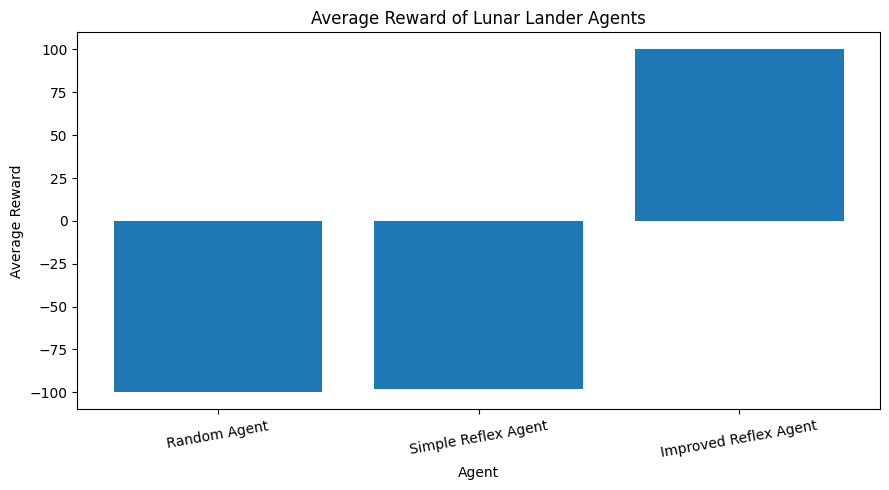

In [63]:
import matplotlib.pyplot as plt


plt.figure(
    figsize=(9, 5)
)

plt.bar(
    results["Agent"],
    results["Average Reward"]
)

plt.title(
    "Average Reward of Lunar Lander Agents"
)

plt.xlabel(
    "Agent"
)

plt.ylabel(
    "Average Reward"
)

plt.xticks(
    rotation=10
)

plt.tight_layout()

plt.show()

Biểu đồ độ ổn định

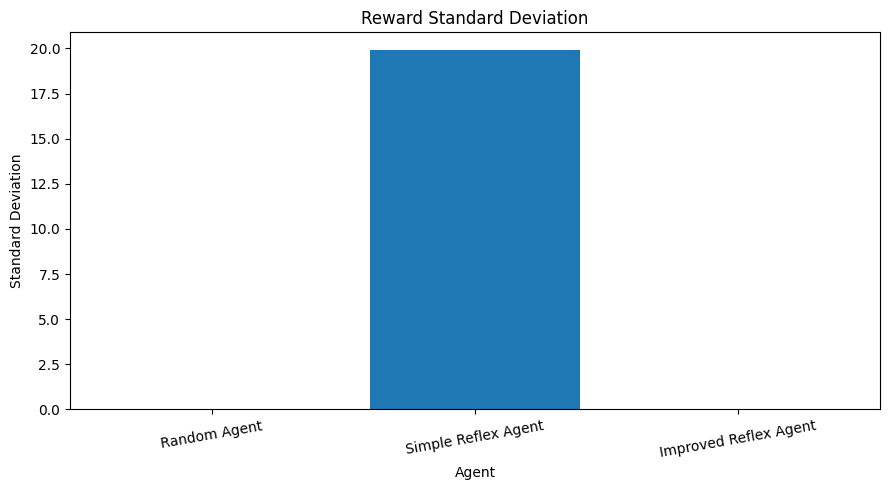

In [64]:
plt.figure(
    figsize=(9, 5)
)

plt.bar(
    results["Agent"],
    results["Std Reward"]
)

plt.title(
    "Reward Standard Deviation"
)

plt.xlabel(
    "Agent"
)

plt.ylabel(
    "Standard Deviation"
)

plt.xticks(
    rotation=10
)

plt.tight_layout()

plt.show()